# Position-level extrapolation in deep mutational scanning models

### a property of the representation, not of the data

This notebook reproduces every table and figure in the accompanying manuscript from the cached
outputs in `results/`. It runs in seconds; nothing is retrained here. The scripts that produced
those outputs are named in each section, and `run_all.sh` reproduces the whole study from raw
data.

**The argument, in four steps.**

1. A held-out-position split is uninterpretable without an untrained control. On a combinatorial
   library, ranking variants by how many substitutions they carry already scores well.
2. The partial Spearman correlation removes that confound directly and validates itself, because
   the trivial baseline must score exactly zero on it.
3. Models that index a substitution by *where* it occurs collapse at held-out positions. This is
   a property of the representation, not a limit of the data — a point an earlier version of
   this work got wrong.
4. Models whose features survive at an unseen position do not collapse. Structure is what carries
   the transfer, and the pattern holds across 217 ProteinGym assays.


## 0. Setup

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
R, FIG = ROOT / "results", ROOT / "results" / "figures"
J = lambda n: json.loads((R / n).read_text()) if (R / n).exists() else {}
C = lambda n: pd.read_csv(R / n) if (R / n).exists() else pd.DataFrame()
show = lambda n, w=900: display(Image(filename=str(FIG / n), width=w)) if (FIG / n).exists() else print("missing:", n)
pd.set_option("display.width", 200, "display.max_columns", 60)
print("results dir:", R)
print("available:", len(list(R.glob("*.csv"))), "csv,", len(list(FIG.glob("*.png"))), "figures")

results dir: /home/user/EvoClassNet/results
available: 22 csv, 19 figures


## 1. Data

Five sources, all public and all fetched by scripts in this repository.


In [2]:
from evoclassnet import data as D
g = D.load_genotypes()
print(f"SARS-CoV-2 RBD deep mutational scan: {len(g):,} unique genotypes")
for t, lab in (("bind","ACE2 binding"), ("expr","expression"), ("escape","antibody escape")):
    print(f"  {lab:18s} {int(g[t].notna().sum()):>7,} labelled   "
          f"(single substitutions: {int((g[t].notna() & (g.n_sub==1)).sum()):,})")
print(f"\nsubstitution counts: median {int(g.n_sub.median())}, max {int(g.n_sub.max())}")

SARS-CoV-2 RBD deep mutational scan: 124,197 unique genotypes
  ACE2 binding       105,526 labelled   (single substitutions: 3,602)
  expression         116,258 labelled   (single substitutions: 3,608)
  antibody escape      2,029 labelled   (single substitutions: 2,029)

substitution counts: median 3, max 11


In [3]:
from evoclassnet import structure as S
f, mask, adj, names = S.compute()
iface = [i + 1 + S.OFFSET for i in range(201) if mask[i] and f[i, names.index("is_interface")] > 0.5]
print(f"PDB 6M0J: {int(mask.sum())}/201 positions resolved, {int(adj.sum()//2)} contact edges")
print("descriptors:", names)
print("\nACE2 interface recovered from the structure (spike numbering):")
print(" ", "  ".join(str(s) for s in iface))
print("\nThese are the known ACE2 contacts, which is the check that the geometry pipeline works.")

PDB 6M0J: 194/201 positions resolved, 913 contact edges
descriptors: ['rsa_unbound', 'rsa_bound', 'd_rsa', 'min_dist_ace2', 'contact_number', 'depth', 'bfactor', 'is_interface']

ACE2 interface recovered from the structure (spike numbering):
  417  446  449  453  455  456  475  476  484  486  487  489  493  496  498  500  501  502  505

These are the known ACE2 contacts, which is the check that the geometry pipeline works.


## 2. The two evaluation designs

The held-out-position split assigns a variant to a partition only if *every* position it mutates
belongs to that partition. The assertion below is the one the whole paper rests on.


In [4]:
for seed in range(3):
    tr, va, te = D.split_heldout_sites(g, seed)
    tr_s = set().union(*[g.sites.iloc[i] for i in tr])
    te_s = set().union(*[g.sites.iloc[i] for i in te])
    assert not (tr_s & te_s)
    print(f"seed {seed}: train {len(tr):>6,} ({len(tr_s)} positions) | "
          f"test {len(te):>5,} ({len(te_s)} positions) | shared positions: {len(tr_s & te_s)}")

seed 0: train 47,645 (151 positions) | test 1,499 (30 positions) | shared positions: 0


seed 1: train 47,234 (151 positions) | test 1,659 (30 positions) | shared positions: 0


seed 2: train 53,917 (151 positions) | test 1,509 (30 positions) | shared positions: 0


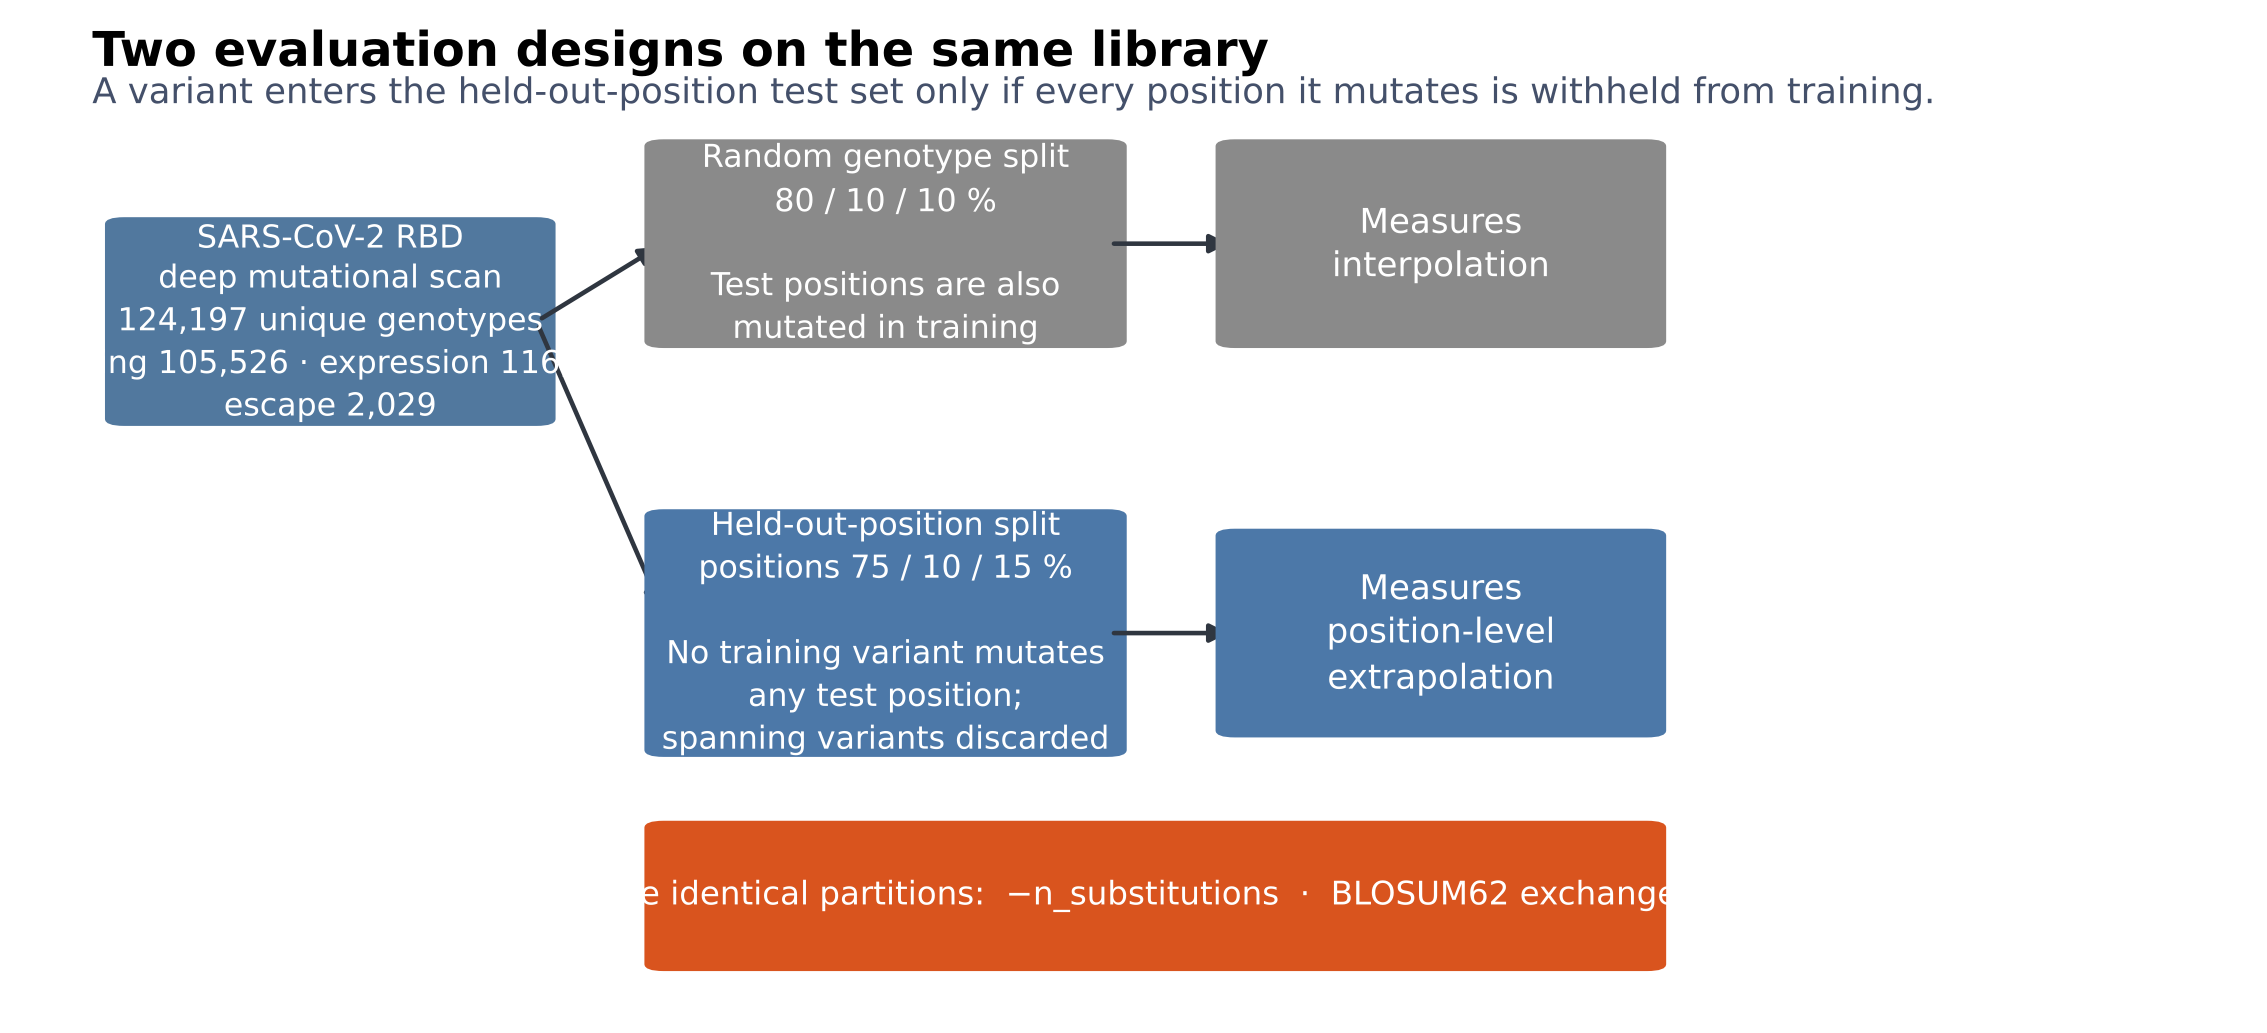

In [5]:
show("schema1_design.png")

## 3. The confound, and a metric that removes it

A model that has learned nothing about the withheld positions still orders the test set, because
fitness falls with the number of substitutions. The partial Spearman correlation regresses the
substitution count out of the ranks of both prediction and measurement. It has a built-in check:
the mutation-count baseline must score exactly zero on it.


In [6]:
from evoclassnet.metrics import evaluate
rng = np.random.default_rng(0); n = 4000
nsub = rng.integers(1, 6, n)
y = -0.8 * nsub + rng.normal(0, 1, n)
demo = {"mutation count only": -nsub.astype(float),
        "genuine predictor":   y + rng.normal(0, 0.5, n)}
rows = []
for lab, p in demo.items():
    r = evaluate(y, p, nsub)
    rows.append(dict(predictor=lab, spearman=round(r["spearman"], 3),
                     partial=round(r["spearman_partial"], 3)))
display(pd.DataFrame(rows))
print("A mutation-count-only predictor looks respectable on Spearman and is exactly zero on the partial.")

,predictor,spearman,partial
0,mutation count only,0.757,-0.002
1,genuine predictor,0.946,0.886


A mutation-count-only predictor looks respectable on Spearman and is exactly zero on the partial.


## 4. SARS-CoV-2 RBD: the full metric panel

In [7]:
panel = C("table_panel.csv")
if len(panel):
    for sp in ("random", "heldout_sites"):
        d = panel[(panel.split == sp) & (panel.task == "ACE2 binding")]
        print(f"\n--- {sp}, ACE2 binding")
        display(d[["family","model","seeds","spearman","spearman_partial","pearson",
                   "r2","auroc_deleterious","precision_at_50","n"]])
else:
    print("results/table_panel.csv not present: run scripts/run_study2.py then scripts/analyze2.py")


--- random, ACE2 binding


,family,model,seeds,spearman,spearman_partial,pearson,r2,auroc_deleterious,precision_at_50,n
0,untrained,Mutation count,5,0.478 ± 0.005,-0.001 ± 0.001,0.470 ± 0.005,0.151 ± 0.010,0.735 ± 0.005,0.012 ± 0.018,10540
3,untrained,BLOSUM62,5,0.417 ± 0.007,0.234 ± 0.008,0.420 ± 0.006,-1.821 ± 0.047,0.712 ± 0.002,0.040 ± 0.020,10540
6,untrained,ESM-2 zero-shot,5,0.075 ± 0.004,-0.005 ± 0.010,0.081 ± 0.004,-1.750 ± 0.041,0.539 ± 0.003,0.012 ± 0.018,10540
9,transferable,Physicochemical ridge,5,0.726 ± 0.004,0.622 ± 0.006,0.689 ± 0.005,0.475 ± 0.007,0.863 ± 0.004,0.048 ± 0.018,10540
12,transferable,k-NN (features),5,0.646 ± 0.007,0.533 ± 0.008,0.655 ± 0.006,0.311 ± 0.008,0.819 ± 0.005,0.036 ± 0.030,10540
15,transferable,Gradient boosting,5,0.746 ± 0.004,0.653 ± 0.006,0.775 ± 0.003,0.599 ± 0.004,0.873 ± 0.004,0.044 ± 0.026,10540
18,transferable,Structure GNN,5,0.733 ± 0.042,0.646 ± 0.052,0.760 ± 0.045,0.459 ± 0.048,0.864 ± 0.019,0.044 ± 0.033,10540
21,position-indexed,Additive ridge,5,0.874 ± 0.004,0.834 ± 0.006,0.806 ± 0.005,0.649 ± 0.008,0.933 ± 0.004,0.204 ± 0.064,10540
24,position-indexed,Global epistasis,5,0.887 ± 0.005,0.850 ± 0.006,0.935 ± 0.001,0.875 ± 0.003,0.939 ± 0.004,0.284 ± 0.075,10540
27,position-indexed,EvoClassNet,5,0.890 ± 0.011,0.857 ± 0.013,0.958 ± 0.021,0.909 ± 0.059,0.944 ± 0.009,0.160 ± 0.042,10540



--- heldout_sites, ACE2 binding


,family,model,seeds,spearman,spearman_partial,pearson,r2,auroc_deleterious,precision_at_50,n
33,untrained,Mutation count,10,0.386 ± 0.047,-0.000 ± 0.001,0.350 ± 0.044,0.091 ± 0.079,0.660 ± 0.026,0.046 ± 0.051,1386
36,untrained,BLOSUM62,10,0.410 ± 0.032,0.318 ± 0.034,0.390 ± 0.028,-0.684 ± 0.361,0.709 ± 0.023,0.142 ± 0.063,1386
39,untrained,ESM-2 zero-shot,10,-0.022 ± 0.084,-0.052 ± 0.077,-0.012 ± 0.103,-0.912 ± 0.250,0.500 ± 0.063,0.022 ± 0.039,1386
42,transferable,Physicochemical ridge,10,0.711 ± 0.053,0.648 ± 0.077,0.658 ± 0.045,0.391 ± 0.071,0.859 ± 0.024,0.150 ± 0.079,1386
45,transferable,k-NN (features),10,0.602 ± 0.052,0.530 ± 0.075,0.568 ± 0.057,0.287 ± 0.060,0.803 ± 0.028,0.134 ± 0.072,1386
48,transferable,Gradient boosting,10,0.698 ± 0.052,0.635 ± 0.073,0.666 ± 0.061,0.420 ± 0.082,0.858 ± 0.027,0.104 ± 0.059,1386
51,transferable,Structure GNN,10,0.332 ± 0.172,0.259 ± 0.162,0.293 ± 0.159,-0.047 ± 0.114,0.669 ± 0.079,0.048 ± 0.042,1386
54,position-indexed,Additive ridge,10,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,—,0.500 ± 0.000,—,1386
57,position-indexed,Global epistasis,10,-0.370 ± 0.042,-0.015 ± 0.075,-0.350 ± 0.045,-0.166 ± 0.217,0.342 ± 0.024,0.002 ± 0.006,1386
60,position-indexed,EvoClassNet,10,0.341 ± 0.118,0.187 ± 0.134,0.293 ± 0.129,-0.184 ± 0.203,0.664 ± 0.081,0.072 ± 0.053,1386


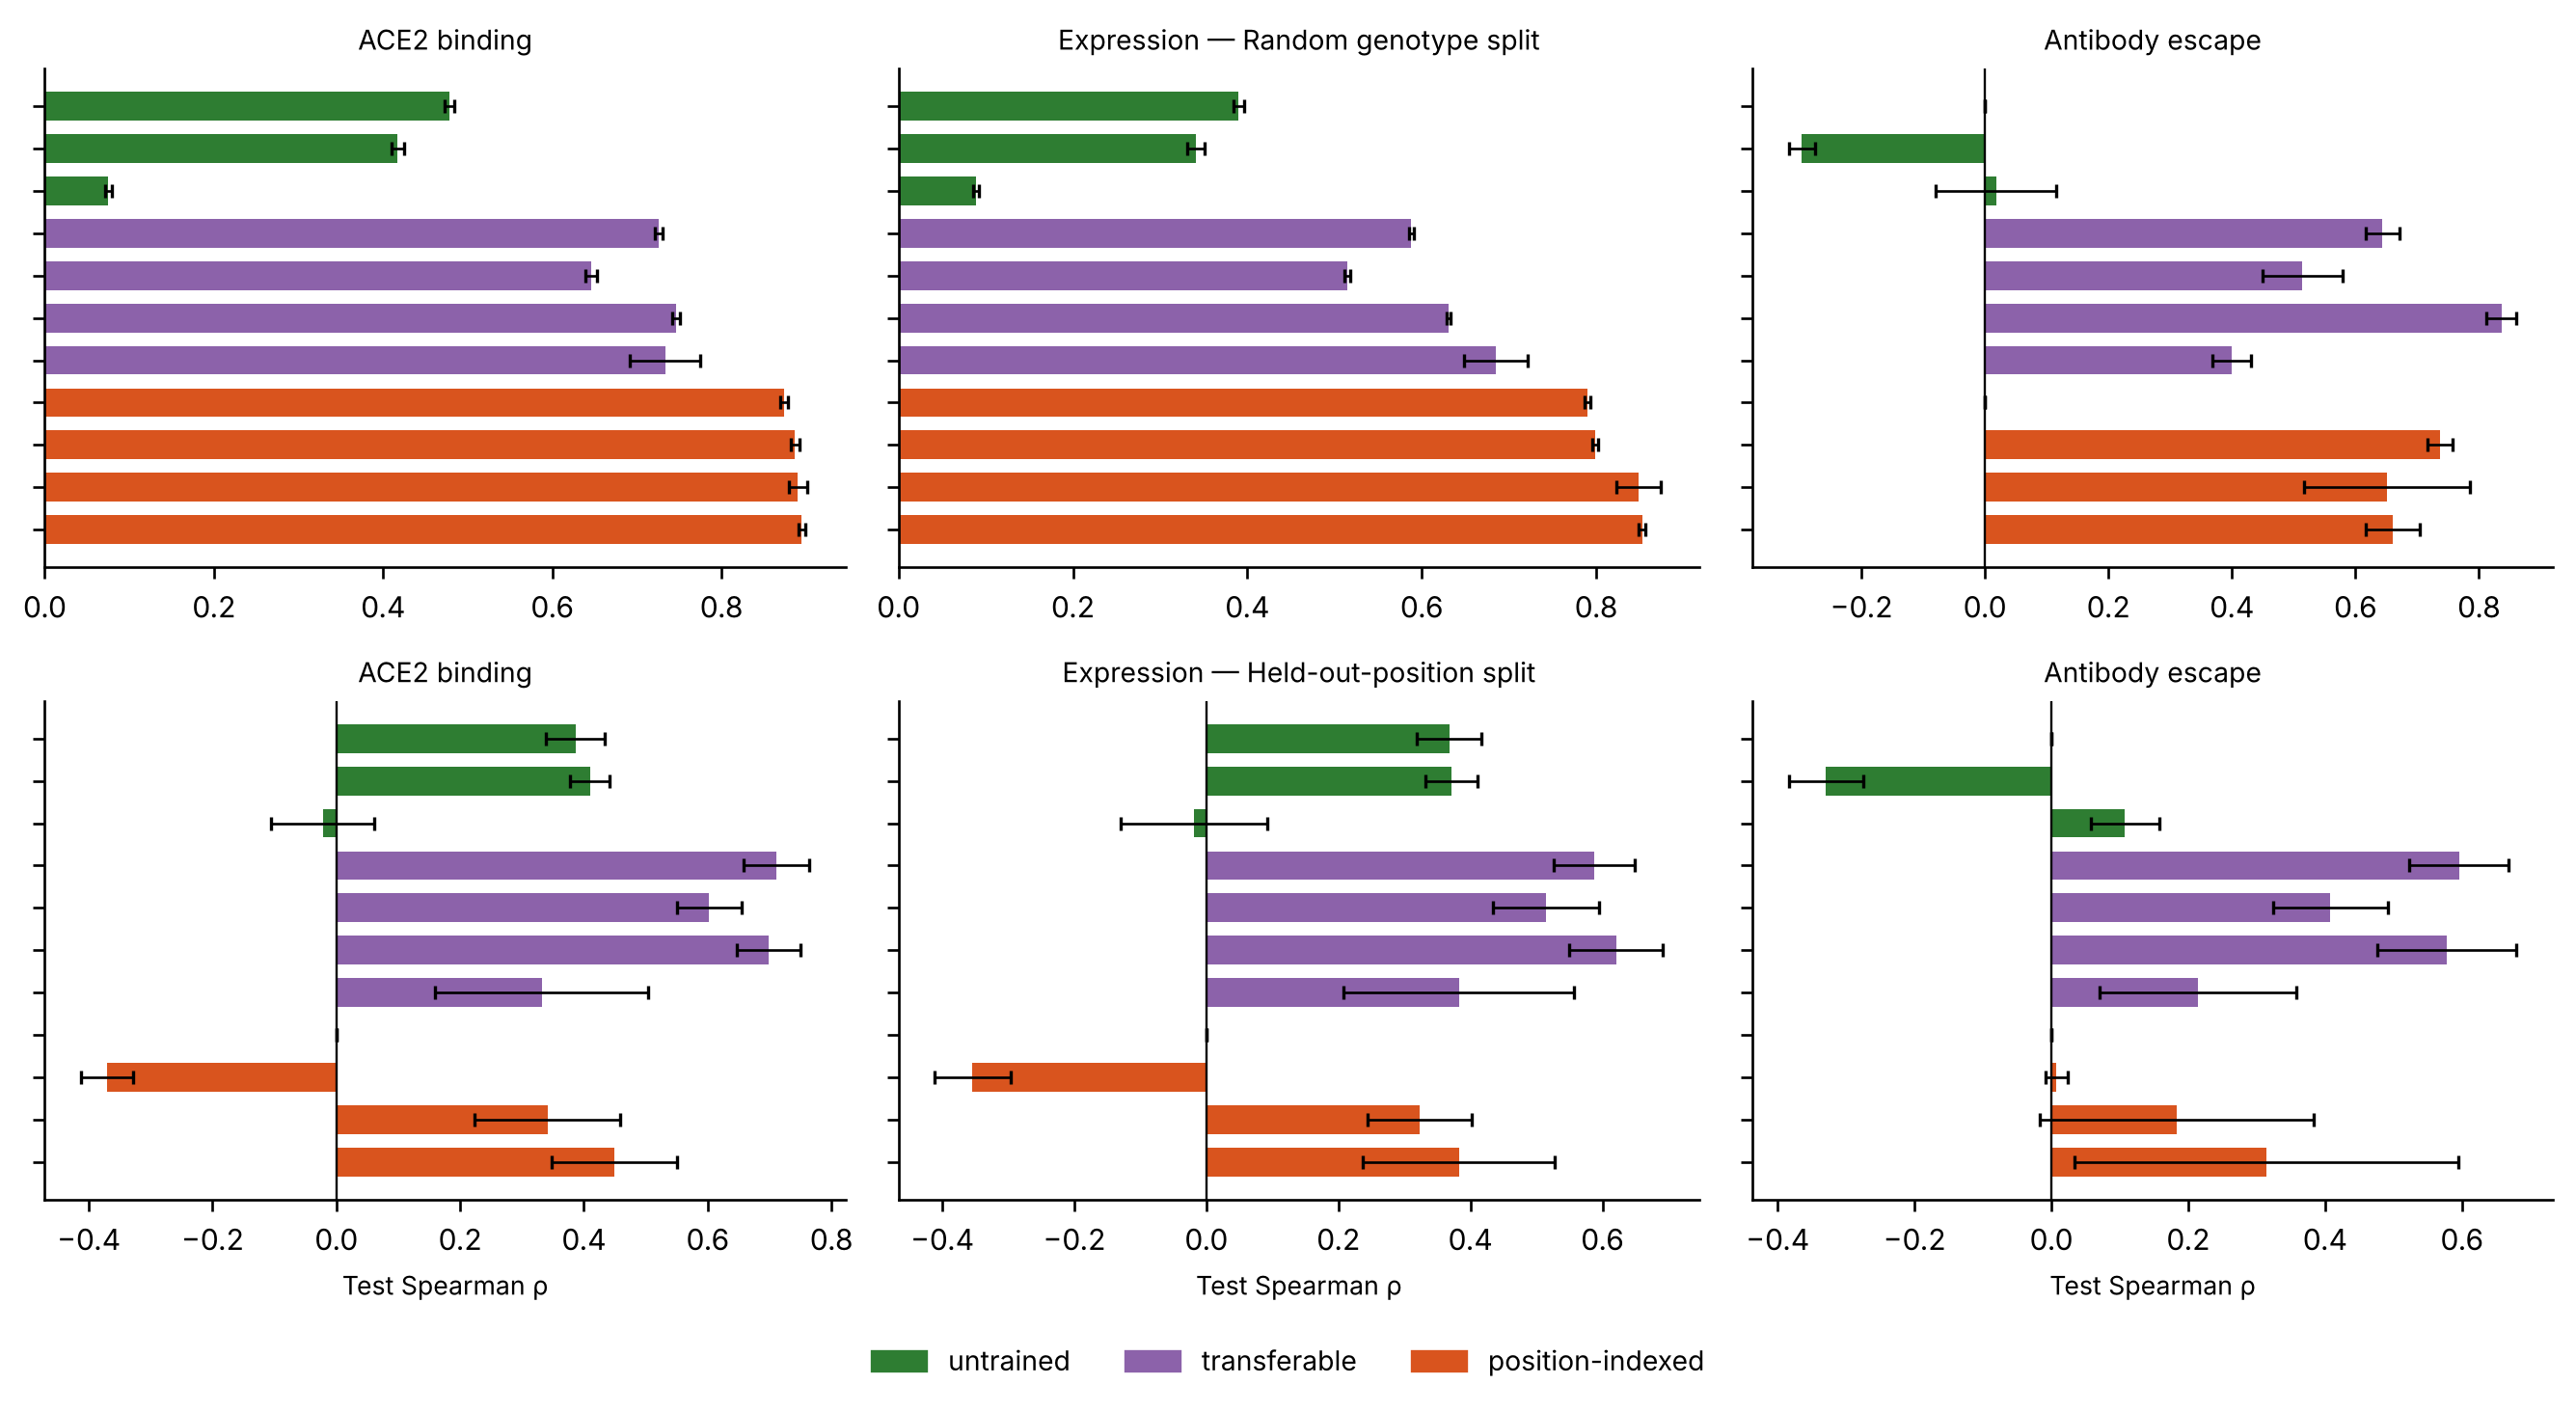

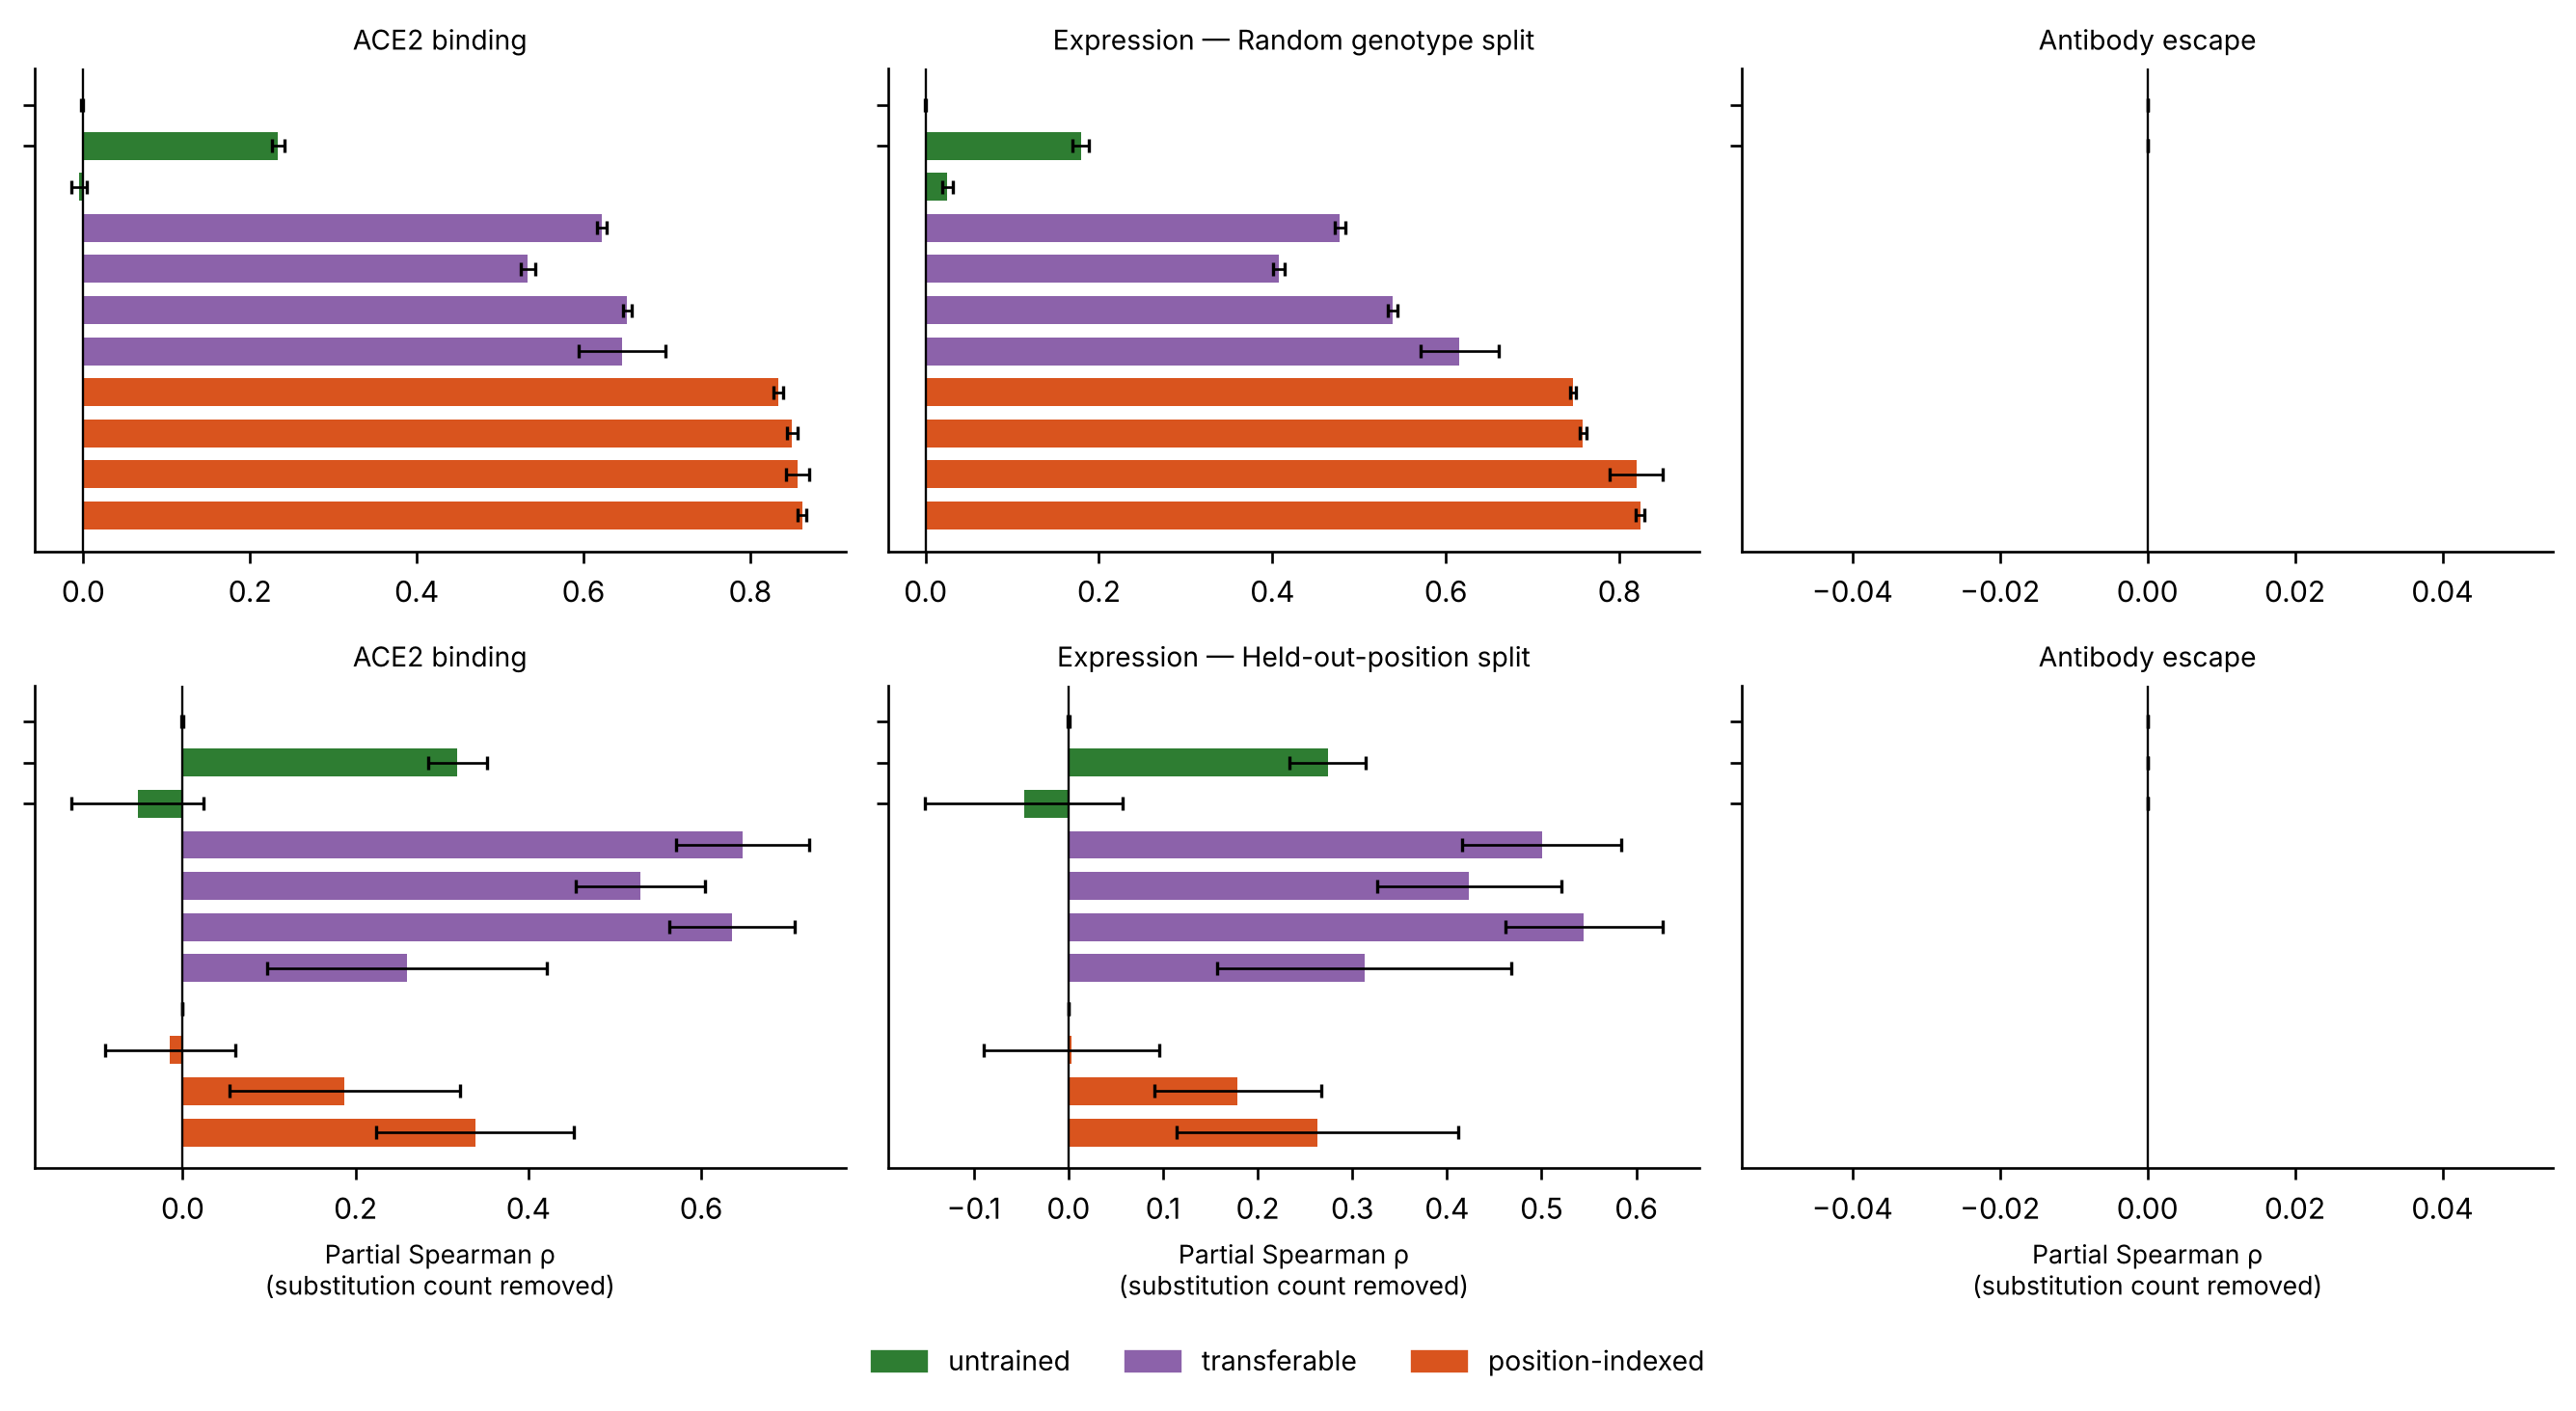

In [8]:
show("fig1_panel_spearman.png"); show("fig2_panel_partial.png")

## 5. Where the signal comes from

`scripts/feature_ablation.py`. Each arm is a ridge regression on a different feature block, all
evaluated on the same held-out-position partitions over 10 seeds.


In [9]:
FEAT = J("feature_ablation.json").get("summary", {})
order = [("nsub_only","Substitution count only"), ("esm_only","ESM-2 zero-shot only"),
         ("chem_only","Residue chemistry only"), ("struct_only","Structure only"),
         ("struct_nointerface","Structure, interface descriptors dropped"),
         ("chem+struct","Chemistry + structure"),
         ("chem+struct+esm","Chemistry + structure + ESM-2")]
rows = []
for arm, lab in order:
    s = FEAT.get(arm, {})
    if not s: continue
    row = {"features": lab}
    for t, tn in (("bind","binding"), ("expr","expression"), ("escape","escape")):
        v = s.get(t, {})
        row[f"{tn} ρ"] = f"{v.get('spearman_mean', np.nan):+.3f}"
        if t != "escape":
            row[f"{tn} partial"] = f"{v.get('partial_mean', np.nan):+.3f}"
    rows.append(row)
display(pd.DataFrame(rows))
print("Escape has no partial column: every escape-labelled variant carries one substitution,")
print("so the substitution count is constant and the confound is absent by construction.")

,features,binding ρ,binding partial,expression ρ,expression partial,escape ρ
0,Substitution count only,+0.386,-0.000,+0.368,+0.000,+0.000
1,ESM-2 zero-shot only,+0.340,-0.004,+0.301,-0.058,+0.108
2,Residue chemistry only,+0.508,+0.371,+0.416,+0.257,+0.340
3,Structure only,+0.644,+0.554,+0.581,+0.485,+0.470
4,"Structure, interface descriptors dropped",+0.615,+0.518,+0.572,+0.477,+0.361
5,Chemistry + structure,+0.706,+0.642,+0.582,+0.494,+0.597
6,Chemistry + structure + ESM-2,+0.712,+0.650,+0.592,+0.506,+0.600


Escape has no partial column: every escape-labelled variant carries one substitution,
so the substitution count is constant and the confound is absent by construction.


### 5a. Positions versus substitutions

`scripts/transfer_by_position.py`. Within a single withheld position, can the model order the
nineteen substitutions available there?


,phenotype,model_median,pct_positive,blosum62,difference,p,n
0,ACE2 binding,0.533,92,0.528,0.005,0.407,300
1,Expression,0.510,90,0.561,0.003,0.926,300
2,Antibody escape,0.570,96,-0.350,0.869,8.65e-30,178


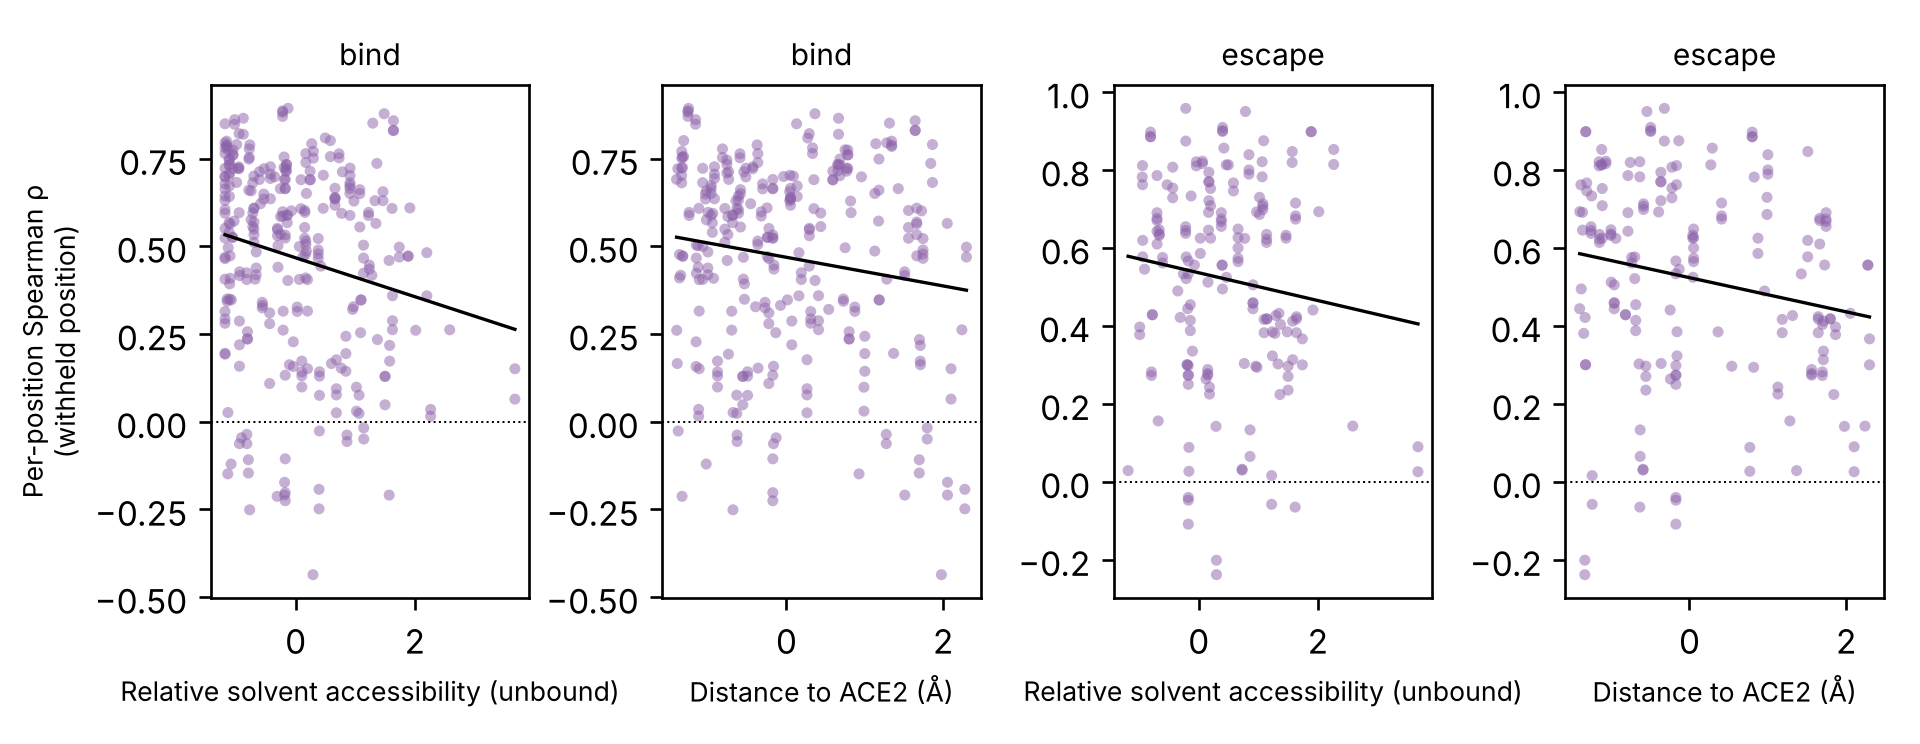

In [10]:
TBP = J("transfer_by_position.json")
rows = []
for t, tn in (("bind","ACE2 binding"), ("expr","Expression"), ("escape","Antibody escape")):
    v = TBP.get(t)
    if not v: continue
    vb = v["vs_blosum"]
    rows.append(dict(phenotype=tn, model_median=round(v["median_rho"], 3),
                     pct_positive=round(100 * v["frac_positive"]),
                     blosum62=round(vb["blosum_median"], 3),
                     difference=round(vb["median_diff"], 3), p=f"{vb['p']:.3g}", n=vb["n"]))
display(pd.DataFrame(rows))
show("fig8_transfer_by_position.png")

## 6. Does the protein language model help?

`scripts/esm_control.py`. A null result from a large pretrained model invites the suspicion of a
broken pipeline, so the model is checked on a protein it should find easy, and the domain is
scored both alone and inside the full spike protein it belongs to.


,setting,wt_recovery,median_top_prob
0,ubiquitin,80.3%,0.796
1,rbd fragment,11.8%,0.096
2,rbd in spike,17.6%,0.099


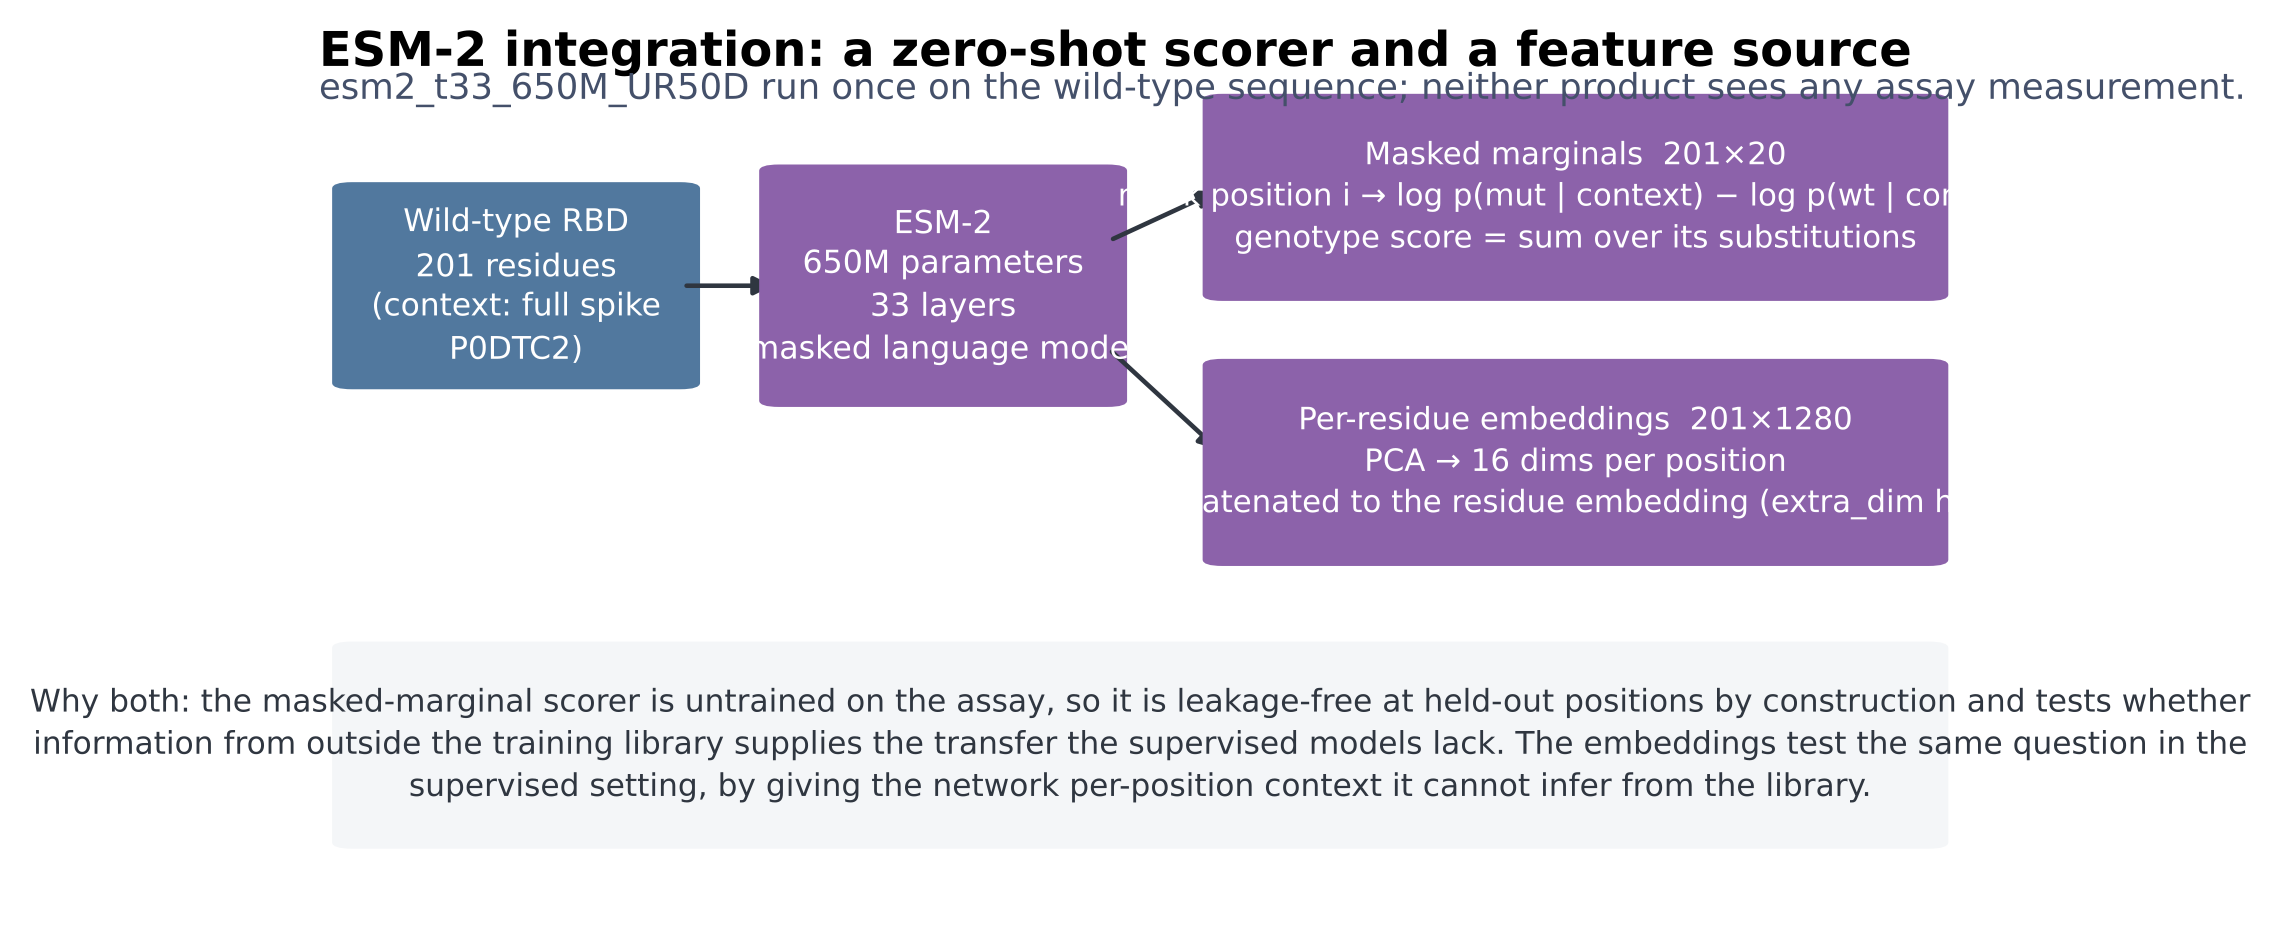

In [11]:
E = J("esm_control.json")
if E:
    display(pd.DataFrame([
        dict(setting=k.replace("_", " "), wt_recovery=f"{v['recovery']:.1%}",
             median_top_prob=round(v["median_top_prob"], 3))
        for k, v in E.items()]))
else:
    print("results/esm_control.json not present: run scripts/esm_control.py")
show("schema3_plm.png")

## 7. Does it hold across proteins? 217 ProteinGym assays

`scripts/run_proteingym.py`. The same comparison on every substitution assay in ProteinGym v1.3.
Two extra baselines make the decomposition clean: a model that knows only *which position* is
mutated, and one that knows only *which residue change* is made.


In [12]:
T = C("table_proteingym.csv")
if len(T):
    display(T)
    conf = J("proteingym_confound.json")
    print("\nconfound inventory:", json.dumps(conf, indent=1))
else:
    print("run scripts/run_proteingym.py then scripts/analyze_proteingym.py")

,split,family,model,n_assays,median,mean,q25,q75,frac_above_0_2,frac_at_zero
0,Random split,untrained,Mutation count,216,0.000,0.120,0.000,0.178,0.245,0.681
1,Random split,untrained,BLOSUM62,216,0.220,0.209,0.134,0.284,0.546,0.000
2,Random split,position-indexed,Position mean,216,0.665,0.630,0.564,0.732,0.968,0.000
3,Random split,position-indexed,Additive ridge,216,0.000,0.220,0.000,0.546,0.319,0.681
4,Random split,transferable,Residue identity,216,0.402,0.455,0.293,0.632,0.944,0.000
5,Random split,transferable,Chemistry ridge,216,0.455,0.493,0.344,0.650,0.972,0.000
6,Random split,transferable,Chemistry + structure,135,0.590,0.586,0.459,0.718,0.978,0.000
7,Held-out-position split,untrained,Mutation count,212,0.000,0.024,0.000,0.000,0.042,0.830
8,Held-out-position split,untrained,BLOSUM62,212,0.198,0.200,0.123,0.270,0.486,0.000
9,Held-out-position split,position-indexed,Position mean,212,0.000,0.000,0.000,0.000,0.000,1.000



confound inventory: {
 "n_assays": 217,
 "n_with_multi_mutants": 69,
 "frac_with_multi_mutants": 0.318,
 "n_count_above_0_2": 9,
 "median_count_rho_where_multi": 0.012
}


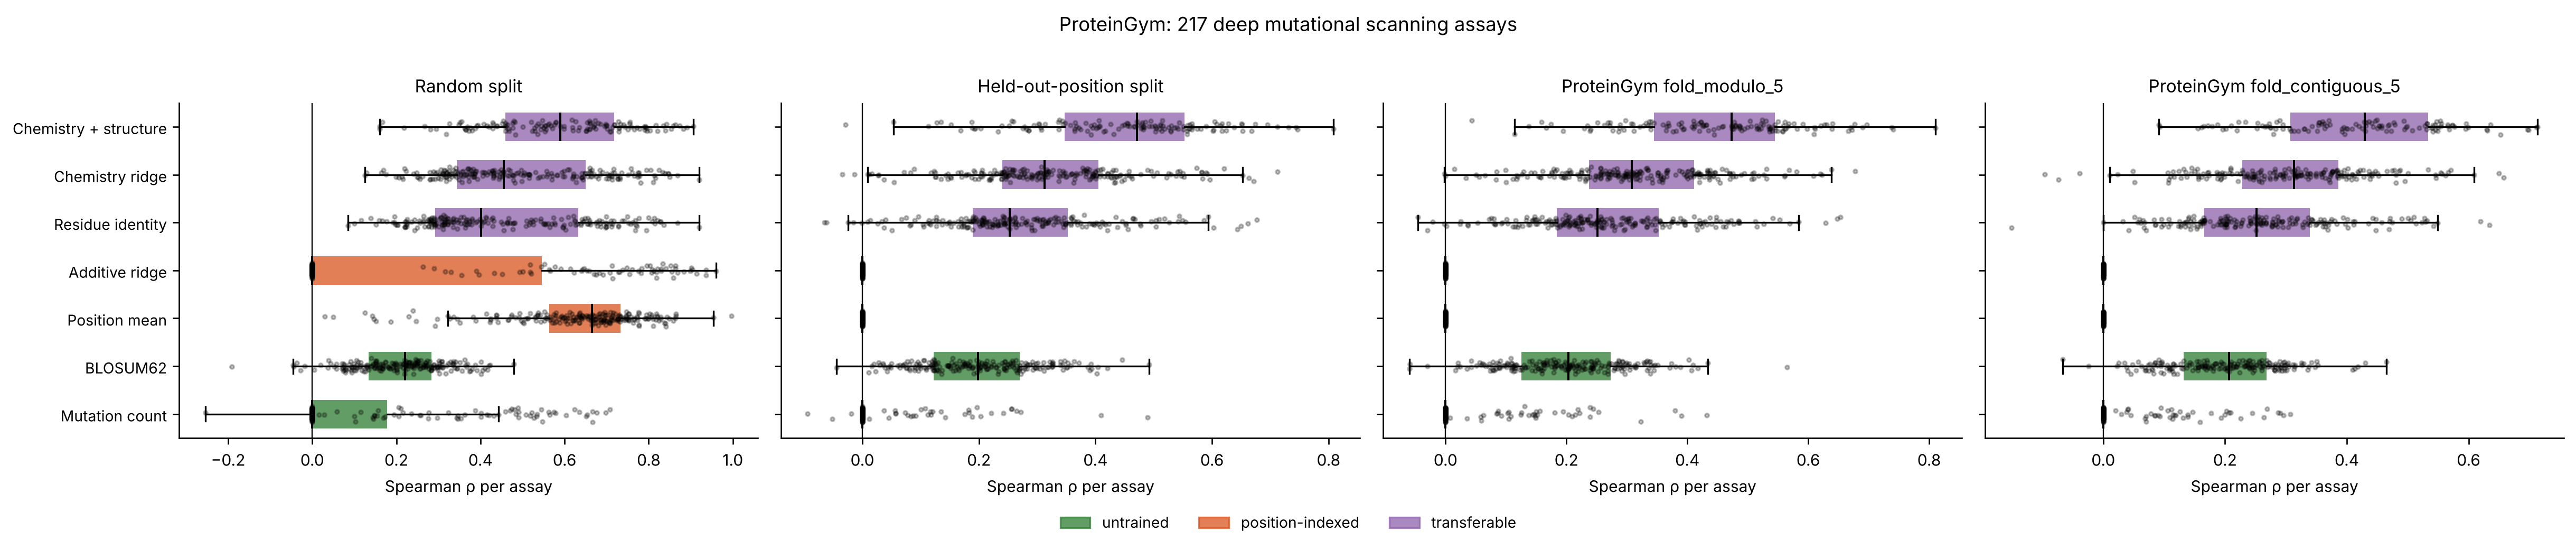

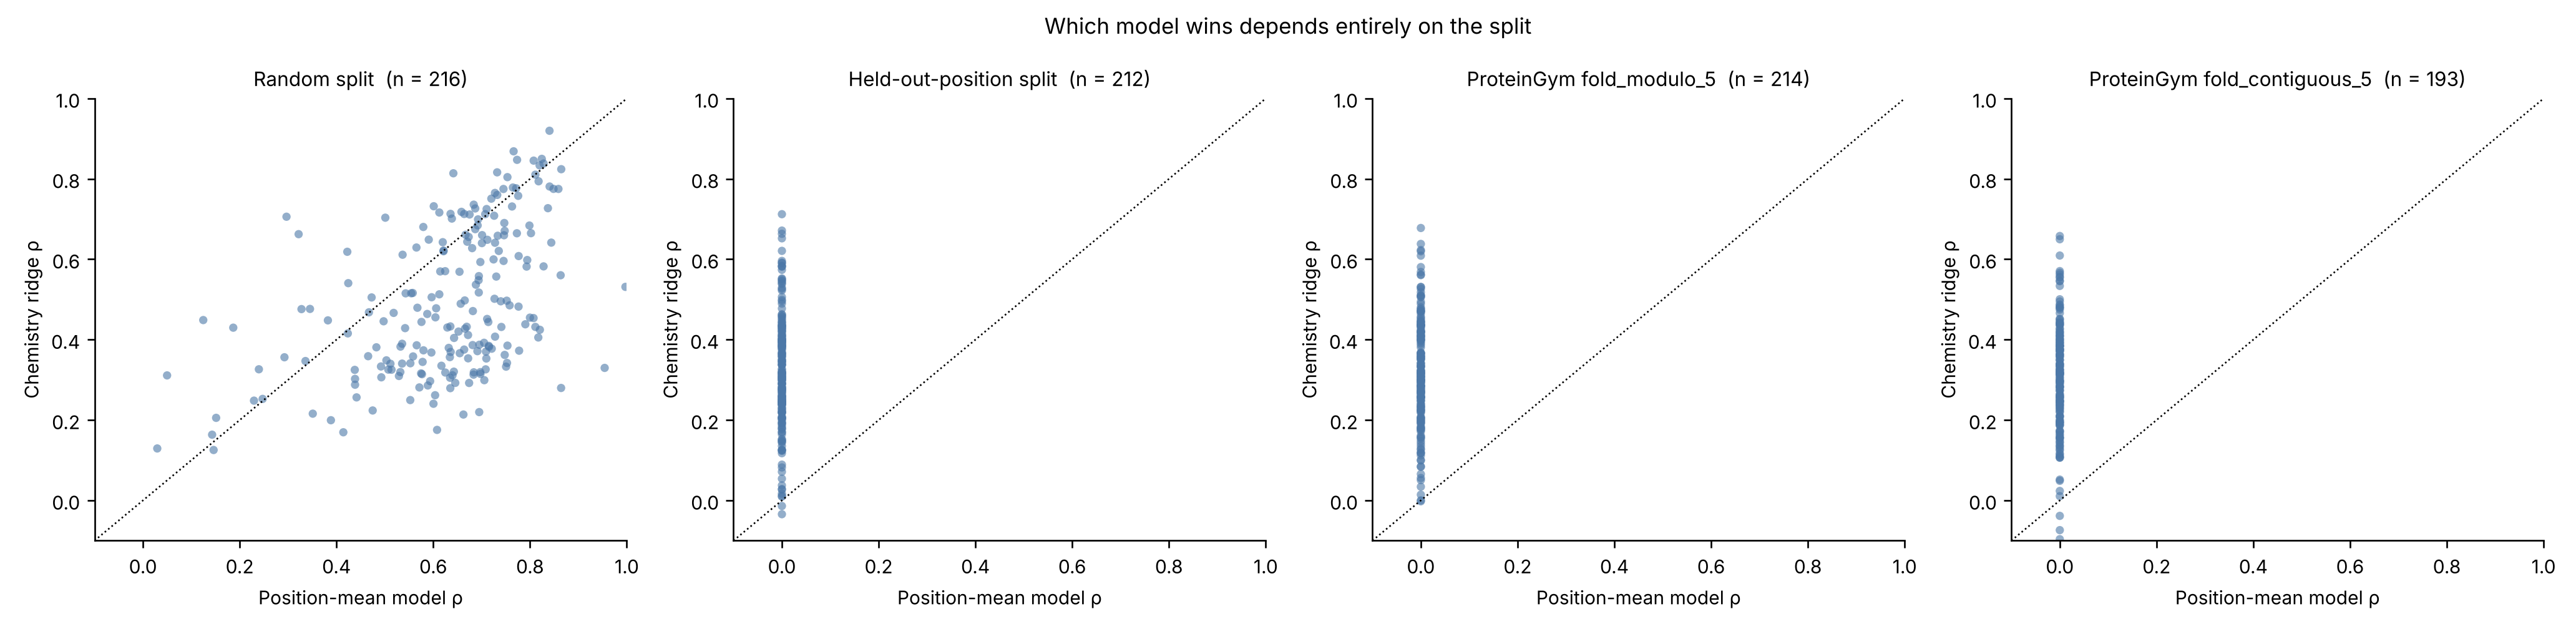

In [13]:
show("fig9_proteingym.png", 1000); show("fig10_proteingym_scatter.png", 820)

In [14]:
Cm = C("table_proteingym_comparisons.csv")
if len(Cm):
    sel = Cm[(Cm.split == "Held-out-position split") & (Cm.reference == "Position mean")]
    display(sel[["model","n_assays","median_diff","ci_lo","ci_hi","p_fdr",
                 "frac_model_better","effect"]])

,model,n_assays,median_diff,ci_lo,ci_hi,p_fdr,frac_model_better,effect
30,Mutation count,212,0.0000,0.0146,0.0334,0.000001,0.156,negligible
31,BLOSUM62,212,0.1983,0.1864,0.2129,0.000000,0.995,large
32,Additive ridge,212,0.0000,0.0000,0.0000,NaN,0.000,negligible
33,Residue identity,212,0.2531,0.2545,0.2925,0.000000,0.976,large
34,Chemistry ridge,212,0.3127,0.3032,0.3410,0.000000,0.991,large
35,Chemistry + structure,132,0.4717,0.4193,0.4719,0.000000,0.992,large


## 7a. Auditing the published leaderboard with a position-only control

`scripts/position_only_audit.py`. ProteinGym publishes per-assay Spearman correlations for eleven
supervised models under each cross-validation scheme. This compares those published numbers,
assay by assay, against a ridge regression told only *which position* a variant mutates.

A model that cannot distinguish an alanine from a tryptophan should not be competitive on a
benchmark of substitution effects.


In [15]:
A = C("table_position_only_audit.csv")
if len(A):
    for sch in ("Random split", "fold_modulo_5"):
        d = A[A.scheme == sch].sort_values("frac_assays_model_beats_position_only")
        if not len(d): continue
        print(f"--- {sch}")
        display(d[["model","n_assays","model_median","position_only_median","median_margin",
                   "frac_assays_model_beats_position_only","n_assays_not_beaten"]])
    print(json.dumps(J("position_only_audit.json"), indent=1))
else:
    print("run scripts/position_only_audit.py")

--- Random split


,model,n_assays,model_median,position_only_median,median_margin,frac_assays_model_beats_position_only,n_assays_not_beaten
9,One-Hot Encodings,216,0.639,0.665,-0.018,0.264,159
4,DeepSequence + One-Hot Encodings,216,0.564,0.665,-0.085,0.278,156
6,MSA_Transformer + One-Hot Encodings,216,0.585,0.665,-0.071,0.282,155
7,TranceptEVE + One-Hot Encodings,216,0.589,0.665,-0.069,0.306,150
8,Tranception + One-Hot Encodings,216,0.585,0.665,-0.064,0.306,150
5,ESM-1v + One-Hot Encodings,216,0.616,0.665,-0.041,0.352,140
0,ESM-1v Embeddings,216,0.685,0.665,0.040,0.602,86
1,MSA Transformer Embeddings,216,0.727,0.665,0.088,0.694,66
2,Tranception Embeddings,216,0.732,0.665,0.065,0.736,57
10,ProteinNPT,216,0.794,0.665,0.119,0.903,21


--- fold_modulo_5


,model,n_assays,model_median,position_only_median,median_margin,frac_assays_model_beats_position_only,n_assays_not_beaten
20,One-Hot Encodings,214,0.014,0.0,0.014,0.603,85
16,ESM-1v + One-Hot Encodings,214,0.439,0.0,0.439,0.977,5
19,Tranception + One-Hot Encodings,214,0.435,0.0,0.435,0.986,3
17,MSA_Transformer + One-Hot Encodings,214,0.441,0.0,0.441,0.986,3
15,DeepSequence + One-Hot Encodings,214,0.421,0.0,0.421,0.995,1
13,Tranception Embeddings,214,0.561,0.0,0.561,0.995,1
11,ESM-1v Embeddings,214,0.574,0.0,0.574,0.995,1
12,MSA Transformer Embeddings,214,0.613,0.0,0.613,0.995,1
21,ProteinNPT,214,0.639,0.0,0.639,0.995,1
18,TranceptEVE + One-Hot Encodings,214,0.461,0.0,0.461,0.995,1


{
 "Random split": {
  "n_models": 11,
  "worst": {
   "model": "One-Hot Encodings",
   "frac_beats": 0.264,
   "n_not_beaten": 159
  },
  "best": {
   "model": "Kermut",
   "frac_beats": 0.94,
   "n_not_beaten": 13
  },
  "median_frac_beats": 0.352
 },
 "fold_modulo_5": {
  "n_models": 11,
  "worst": {
   "model": "One-Hot Encodings",
   "frac_beats": 0.603,
   "n_not_beaten": 85
  },
  "best": {
   "model": "Kermut",
   "frac_beats": 1.0,
   "n_not_beaten": 0
  },
  "median_frac_beats": 0.995
 },
 "fold_contiguous_5": {
  "n_models": 11,
  "worst": {
   "model": "One-Hot Encodings",
   "frac_beats": 0.601,
   "n_not_beaten": 77
  },
  "best": {
   "model": "ProteinNPT",
   "frac_beats": 1.0,
   "n_not_beaten": 0
  },
  "median_frac_beats": 0.995
 }
}


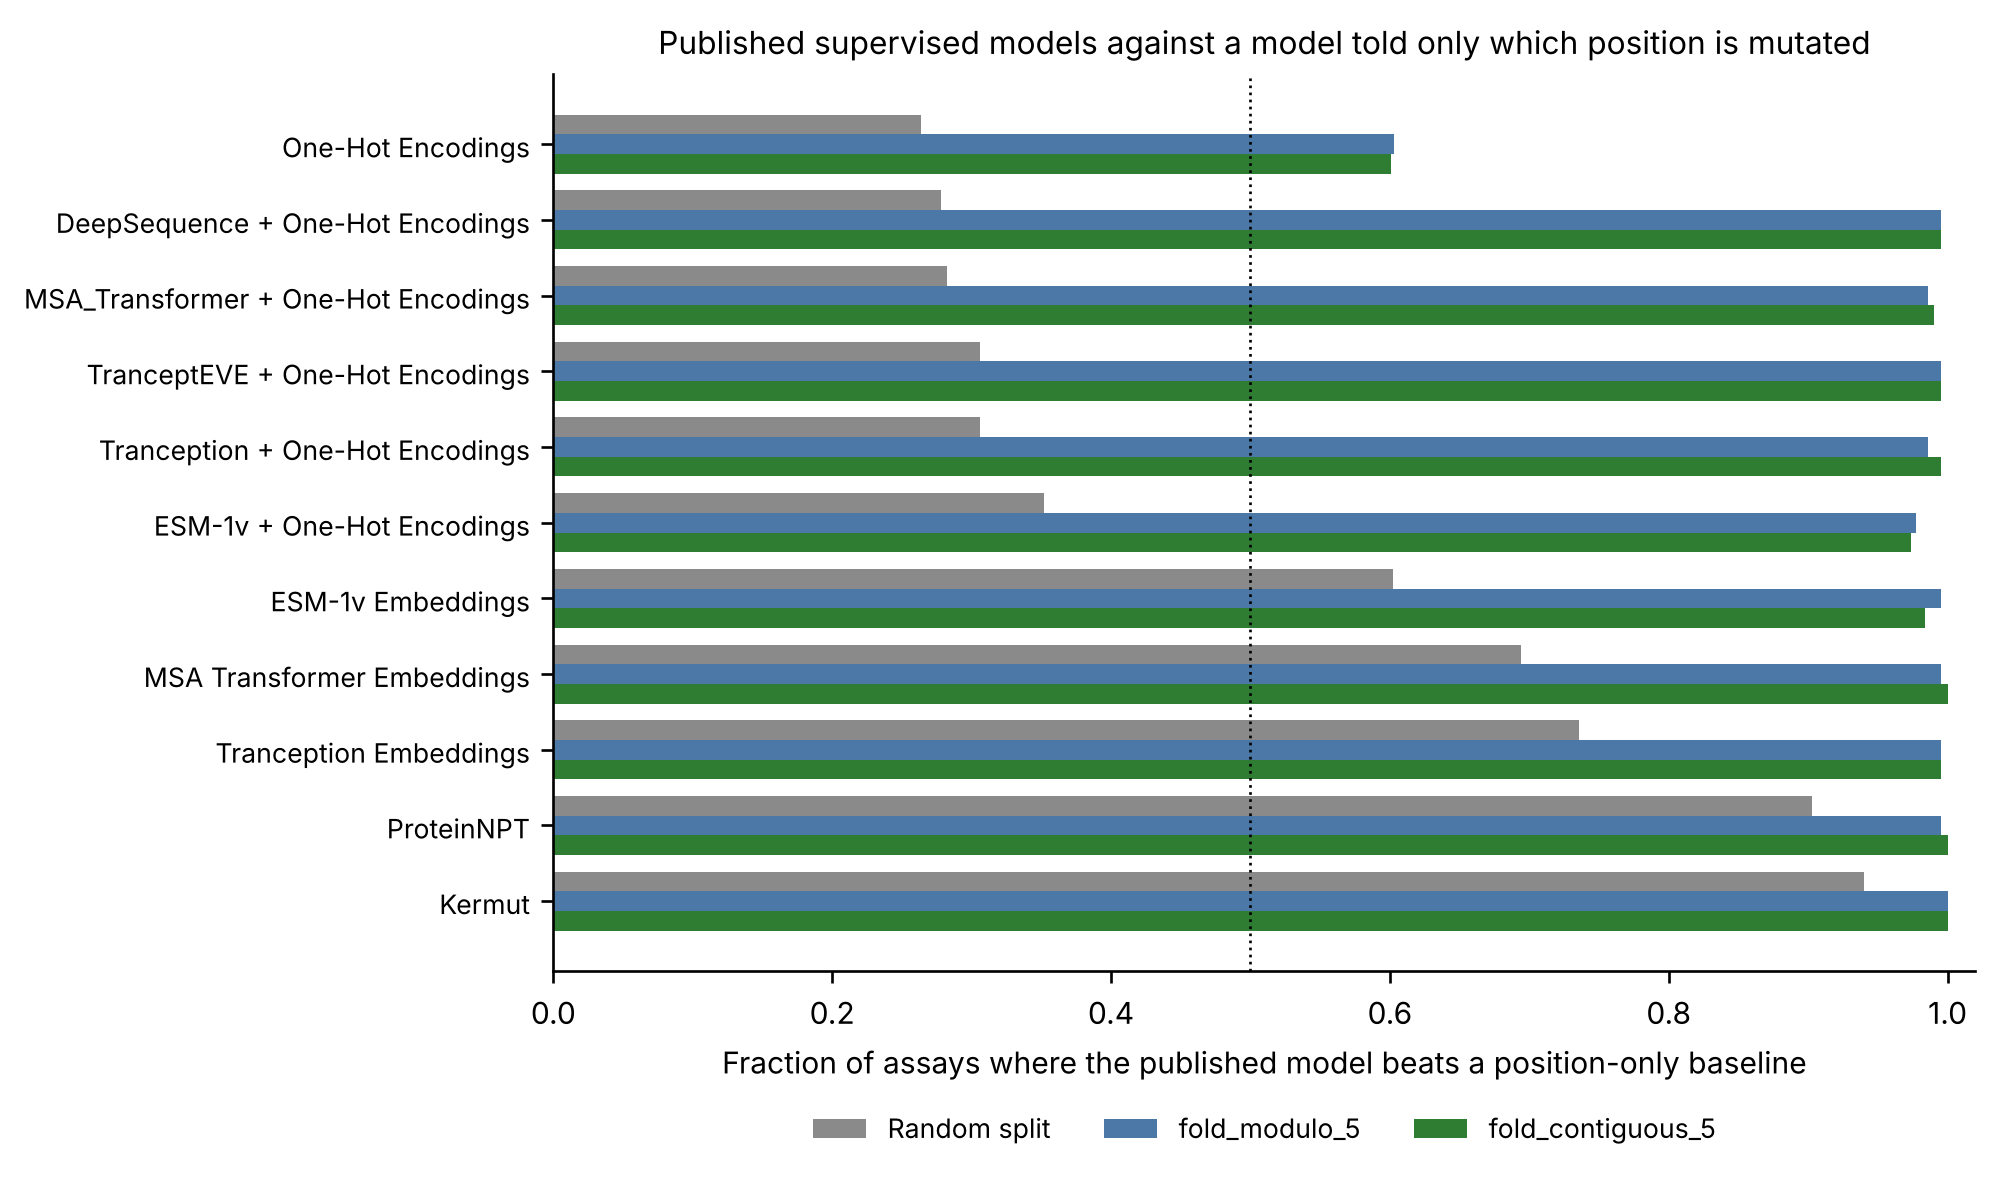

In [16]:
show("fig12_position_only_audit.png", 950)

Under the random split the position-only baseline is not beaten by six of the
eleven published models. Under `fold_modulo_5` it is identically zero and every model clears it.
The models are not weak; the conventional protocol does not show what separates them.

Two caveats, stated in the manuscript: ProteinGym's own random-fold assignments are not
distributed, so an independent 80/20 split over five seeds stands in, and a position-only model
is favoured where each position carries many measured substitutions. Neither affects the
position-based comparisons, where the baseline is zero by construction.

This study's baselines on the published leaderboard's axes:


,source,model_type,model,Random split,fold_modulo_5,fold_contiguous_5,drop (random → modulo)
0,ProteinGym leaderboard,Structure & sequence embedding,Kermut,0.745,0.633,0.593,0.112
1,ProteinGym leaderboard,Sequence embedding,ProteinNPT,0.741,0.588,0.529,0.153
2,ProteinGym leaderboard,Sequence embedding,MSA Transformer Embeddings,0.670,0.562,0.513,0.108
3,ProteinGym leaderboard,Sequence embedding,ESM-1v Embeddings,0.614,0.514,0.479,0.100
4,ProteinGym leaderboard,Sequence embedding,Tranception Embeddings,0.681,0.525,0.439,0.156
5,ProteinGym leaderboard,One-hot Encoding,TranceptEVE + One-Hot Encodings,0.552,0.435,0.435,0.117
6,This work,baseline,Chemistry + structure (this work),0.586,0.449,0.416,0.137
7,ProteinGym leaderboard,One-hot Encoding,Tranception + One-Hot Encodings,0.550,0.413,0.415,0.137
8,ProteinGym leaderboard,One-hot Encoding,MSA_Transformer + One-Hot Encodings,0.540,0.409,0.407,0.131
9,ProteinGym leaderboard,One-hot Encoding,ESM-1v + One-Hot Encodings,0.565,0.394,0.396,0.171


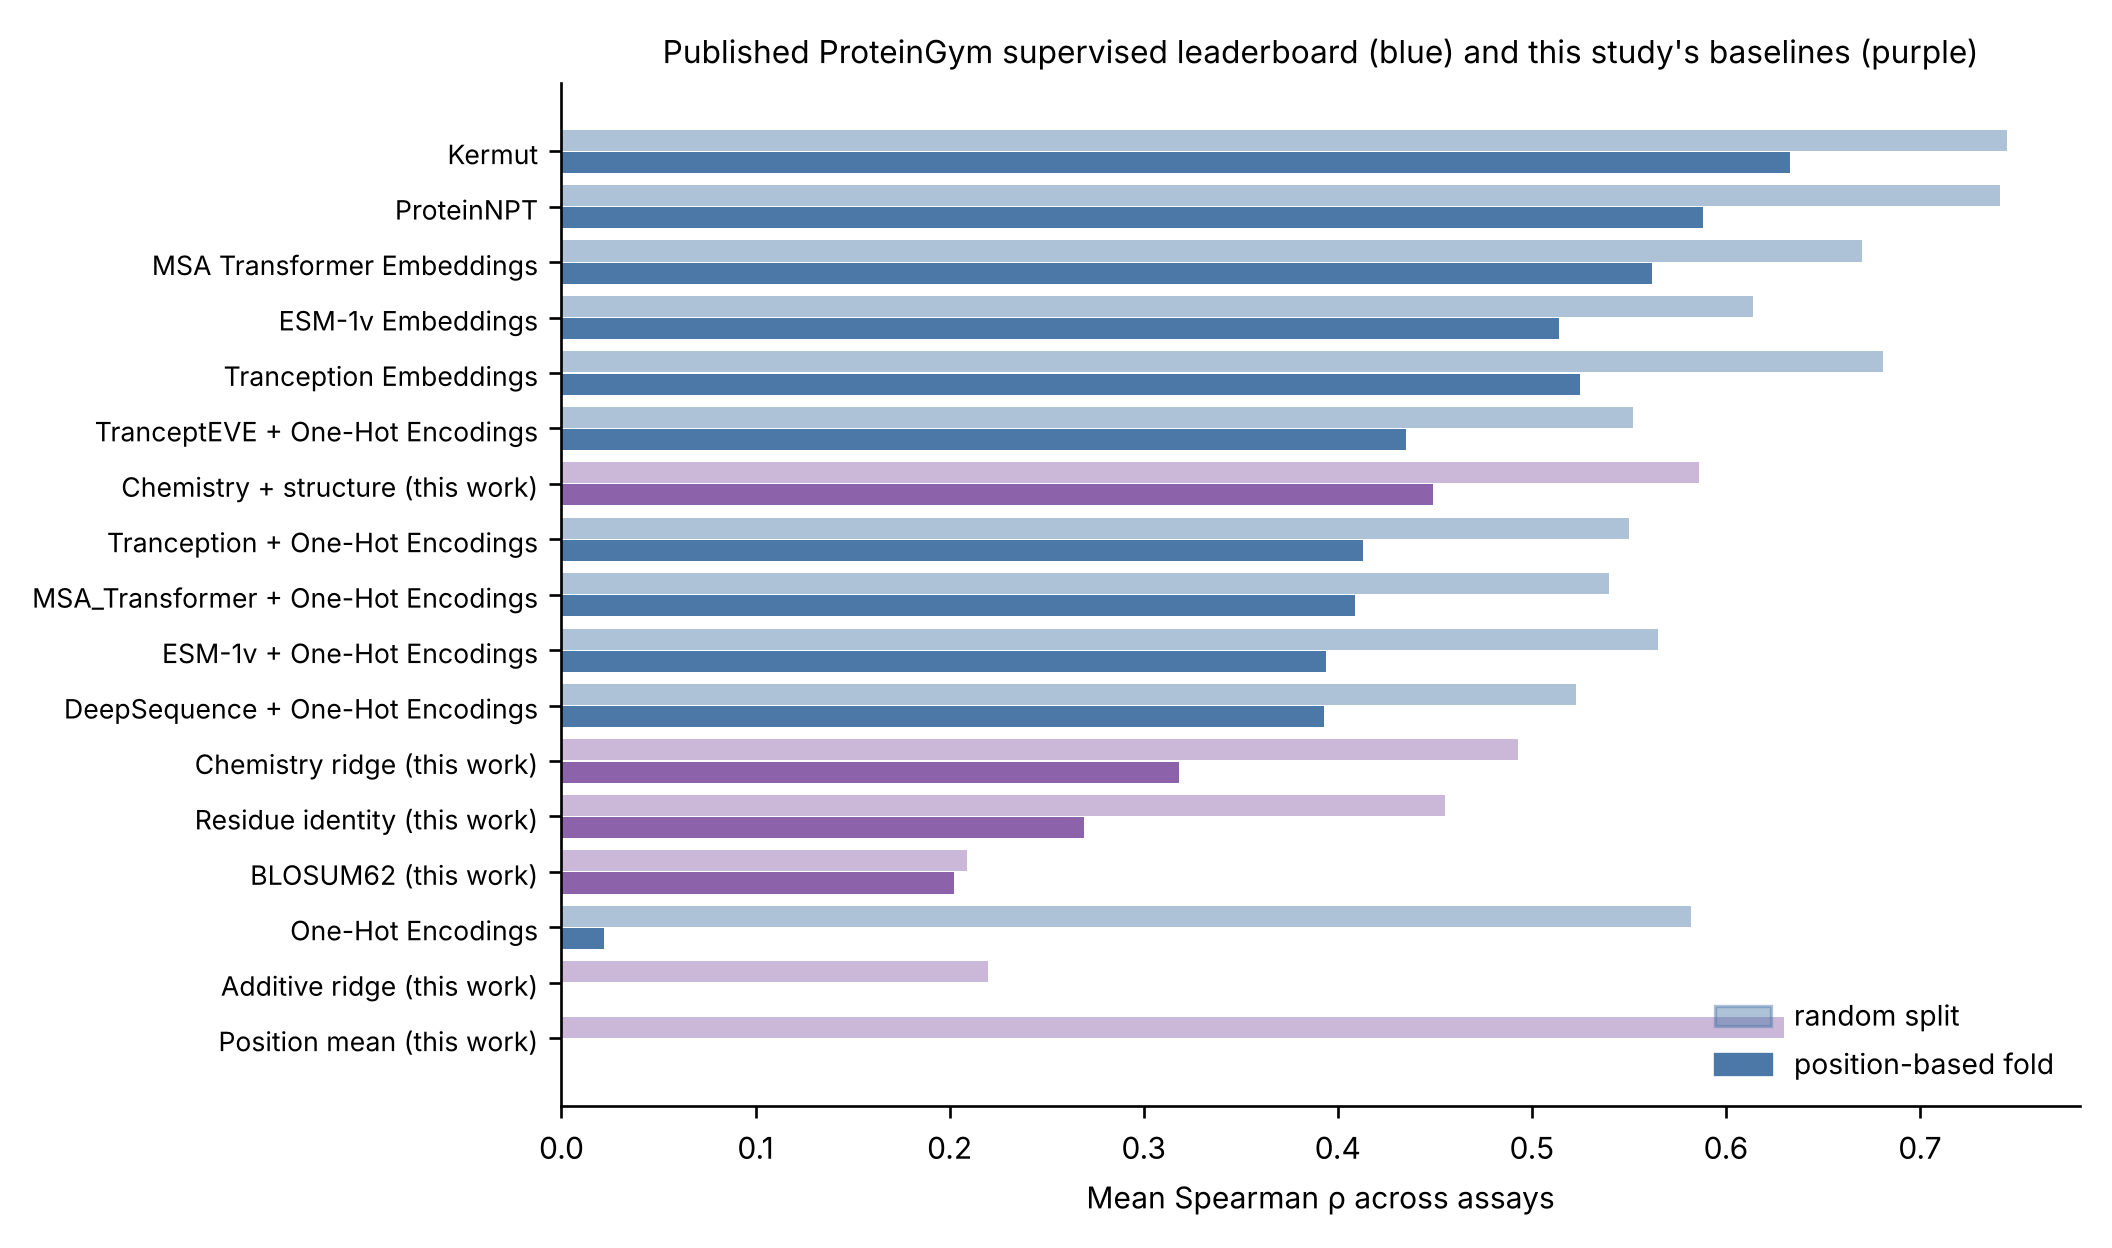

In [17]:
L = C("table_leaderboard_pivot.csv")
if len(L):
    print("This study's baselines on the published leaderboard's axes:")
    display(L)
show("fig11_leaderboard.png", 900)

## 8. A second data type: coronavirus genome classification

`scripts/run_genome_study.py`. Genus classification of coronavirus genomes from NCBI, with the
same question asked and an untrained control that looks only at genome length and base
composition.


,split,family,model,seeds,accuracy,balanced_accuracy,macro_f1,mcc
0,random,untrained,Majority class,10,0.457 ± 0.044,0.250 ± 0.000,0.157 ± 0.010,0.000 ± 0.000
1,random,trivial,Genome length + base composition,10,0.950 ± 0.010,0.953 ± 0.015,0.941 ± 0.016,0.924 ± 0.016
2,random,sequence,5-mer + logistic regression,10,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
3,random,sequence,5-mer + random forest,10,0.997 ± 0.006,0.993 ± 0.013,0.995 ± 0.009,0.995 ± 0.009
4,random,sequence,5-mer + gradient boosting,10,0.998 ± 0.004,0.995 ± 0.009,0.997 ± 0.006,0.996 ± 0.006
5,random,sequence,1D CNN on nucleotides,10,0.990 ± 0.015,0.992 ± 0.009,0.992 ± 0.010,0.985 ± 0.022
6,heldout_species,untrained,Majority class,10,0.497 ± 0.077,0.250 ± 0.000,0.165 ± 0.017,0.000 ± 0.000
7,heldout_species,trivial,Genome length + base composition,10,0.894 ± 0.044,0.914 ± 0.037,0.891 ± 0.038,0.843 ± 0.062
8,heldout_species,sequence,5-mer + logistic regression,10,0.999 ± 0.003,0.998 ± 0.004,0.997 ± 0.007,0.998 ± 0.005
9,heldout_species,sequence,5-mer + random forest,10,0.969 ± 0.038,0.962 ± 0.034,0.968 ± 0.031,0.953 ± 0.053


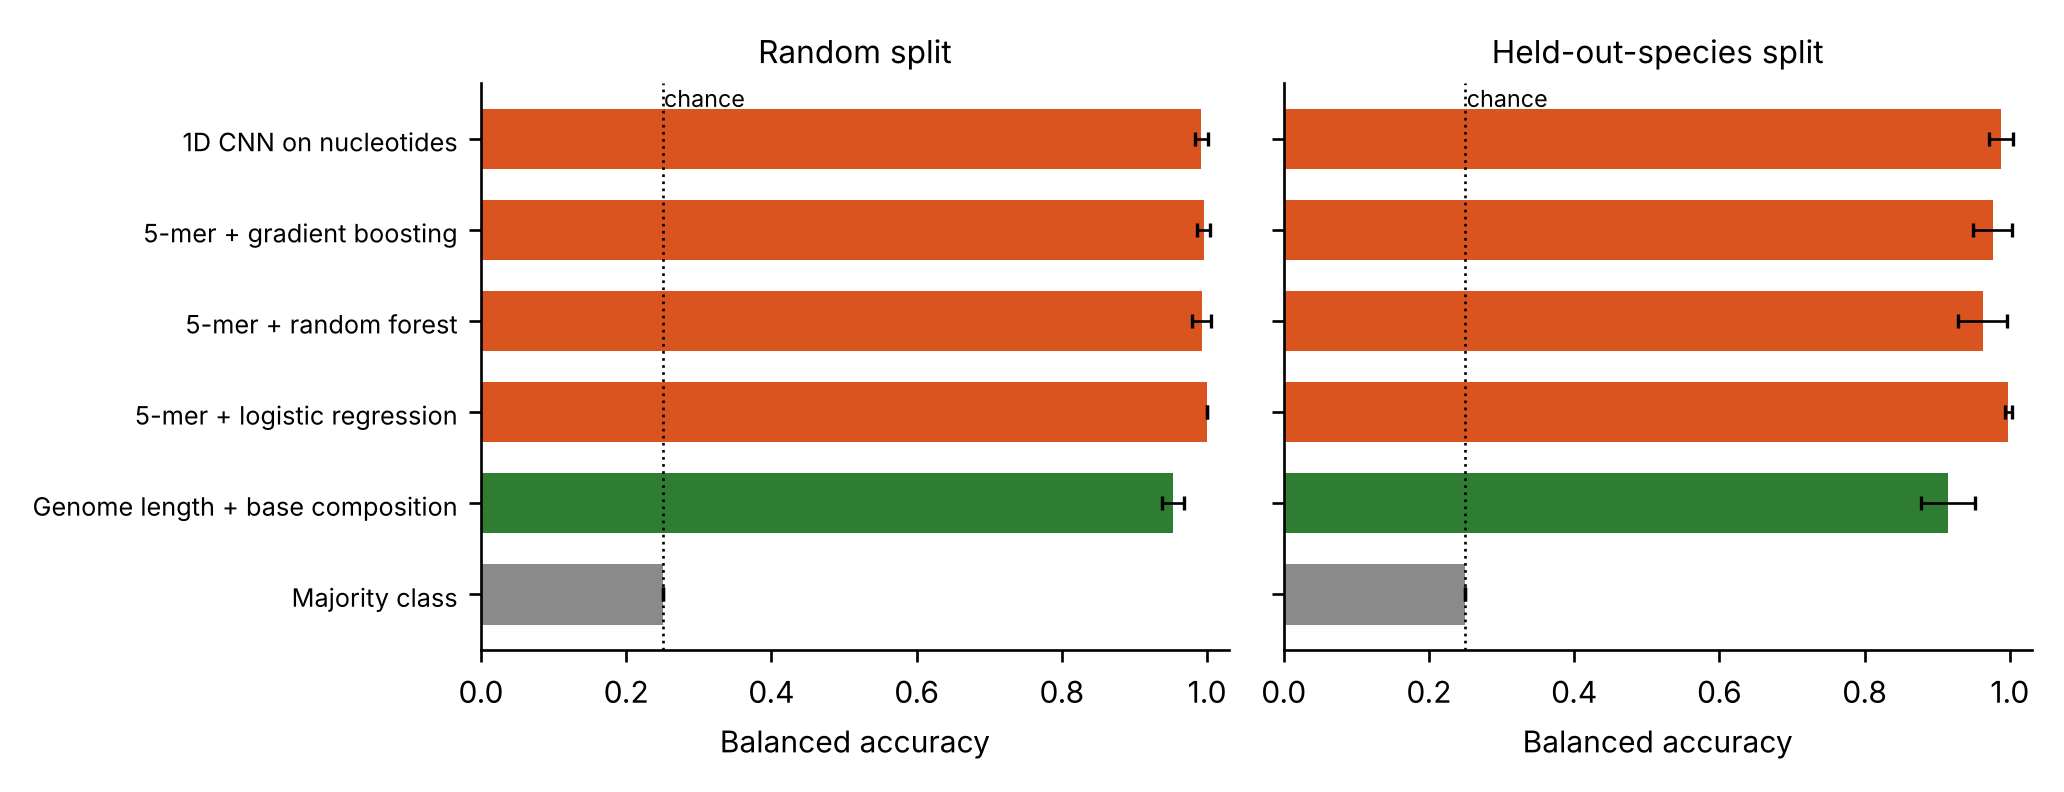

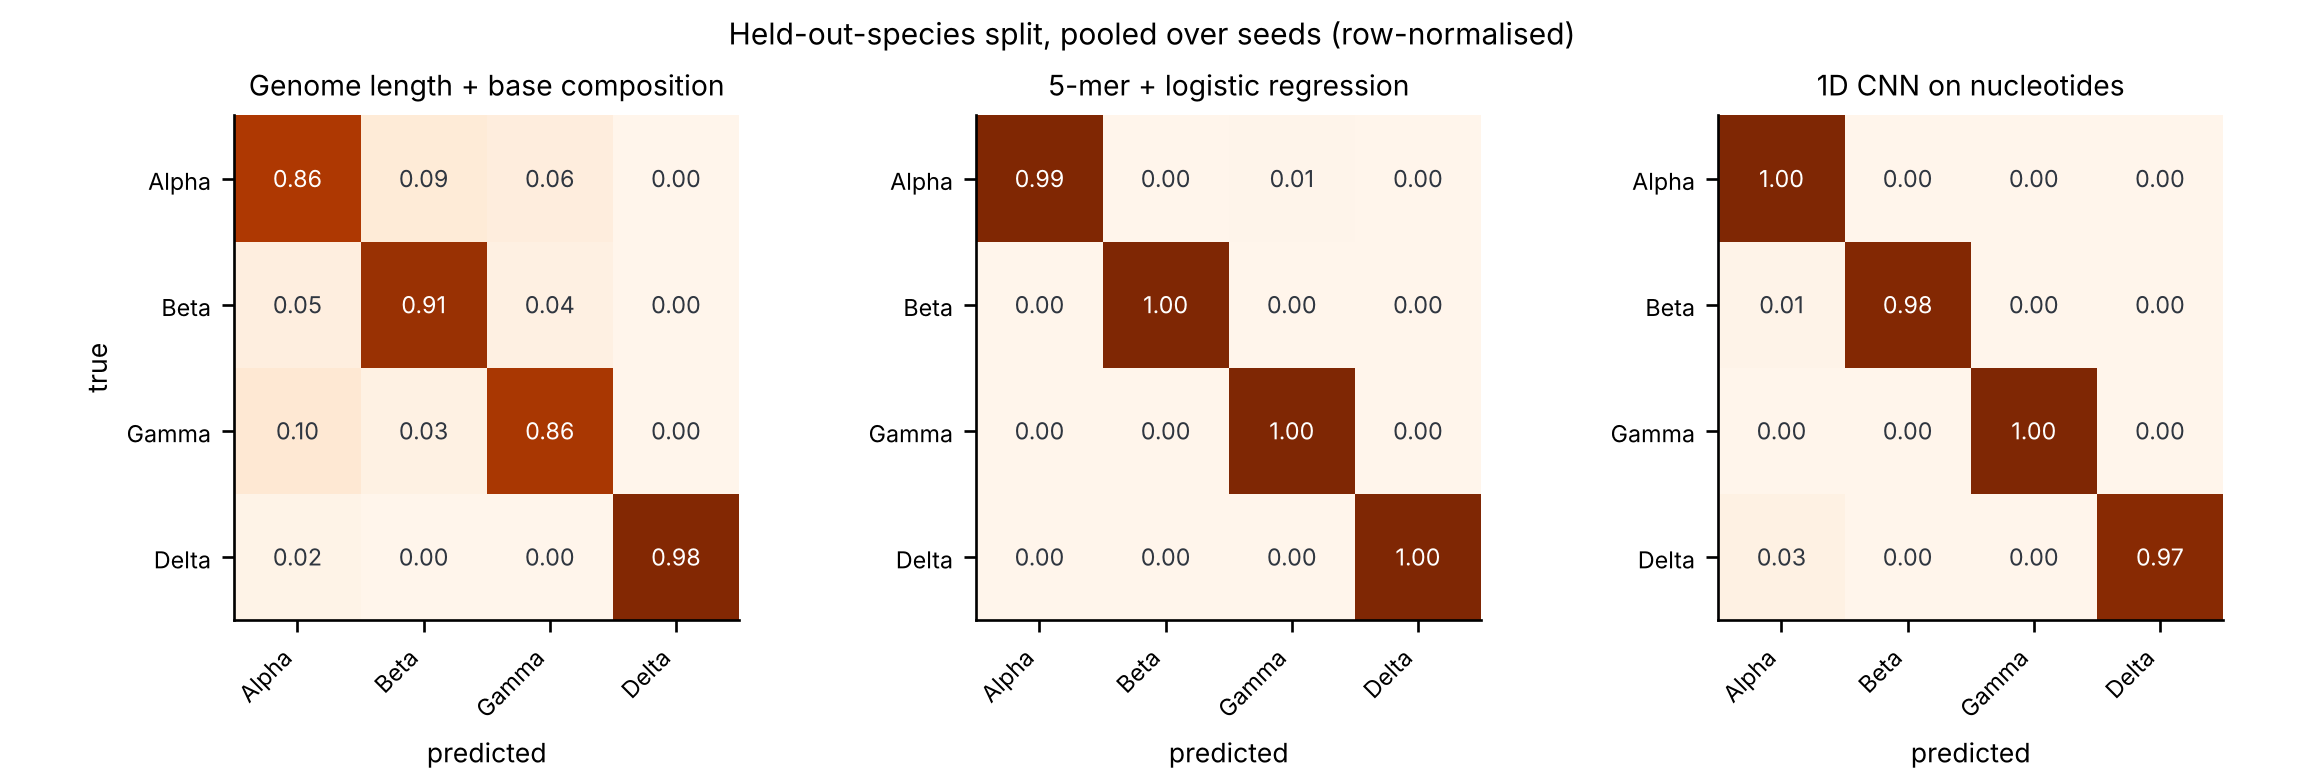

In [18]:
G = C("table_genomes.csv")
if len(G):
    display(G[["split","family","model","seeds","accuracy","balanced_accuracy","macro_f1","mcc"]])
show("fig6_genomes.png", 850); show("fig7_genome_confusion.png", 850)

## 9. Run-to-run instability

`scripts/stability_check.py`. The partition is held fixed and only the weight initialisation
varies.


In [19]:
ST_ = J("stability_check.json")
if ST_:
    d = pd.DataFrame(ST_)
    display(d.groupby("split_seed").bind.agg(["min","median","max","count"]).round(3))
    allv = d.bind.to_numpy()
    print(f"spread across all {len(allv)} runs: {allv.min():+.3f} to {allv.max():+.3f}")
    print("A single run on this benchmark is not a measurement.")

,min,median,max,count
split_seed,,,,
0,0.374,0.387,0.423,3
2,0.236,0.385,0.558,3


spread across all 6 runs: +0.236 to +0.558
A single run on this benchmark is not a measurement.


## 10. What this does and does not show

**Shown.** A held-out-position split needs an untrained control, or better, the partial
correlation. Models that index substitutions by position cannot extrapolate across positions —
and that is about the representation, not the data. Features defined at unseen positions do
extrapolate, structure carries most of it, and the pattern reproduces across the ProteinGym
benchmark.

**Not shown.** That structure carries the transfer is established on one protein with a solved
complex; for a target without one the descriptors would have to be predicted. One language model
at one size with one scoring scheme was evaluated. The genome task is a demonstration that the
evaluation lesson transfers, not a competitive classifier. Seed-level P values describe
reproducibility across partitions of one data set, not inference to other proteins.


In [20]:
print("Tables written by this study:")
for p in sorted(R.glob("table_*.csv")): print("  ", p.name)
for p in sorted(R.glob("proteingym_*.csv")): print("  ", p.name)
print("\nFigures:")
for p in sorted(FIG.glob("*.png")): print("  ", p.name)

Tables written by this study:
   table_ablation.csv
   table_ablation_v2.csv
   table_comparisons.csv
   table_genome_comparisons.csv
   table_genomes.csv
   table_leaderboard_comparison.csv
   table_leaderboard_pivot.csv
   table_main.csv
   table_panel.csv
   table_partial_vs_zero.csv
   table_position_only_audit.csv
   table_proteingym.csv
   table_proteingym_comparisons.csv
   table_stats.csv
   table_structure_effect.csv
   proteingym_per_assay.csv

Figures:
   fig10_proteingym_scatter.png
   fig11_leaderboard.png
   fig12_position_only_audit.png
   fig1_panel_spearman.png
   fig1_random_split.png
   fig2_heldout_sites.png
   fig2_panel_partial.png
   fig3_voc_auroc.png
   fig4_sweep.png
   fig5_per_site.png
   fig6_genomes.png
   fig7_genome_confusion.png
   fig8_transfer_by_position.png
   fig9_proteingym.png
   schema1_design.png
   schema2_backbone.png
   schema3_plm.png
   schema4_structure_gnn.png
   schema5_genome_task.png
